# Técnica 3: TfidfVectorizer + LogisticRegression


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.metrics import classification_report, confusion_matrix, RocCurveDisplay
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

## Carregamento dos dados pré-processados

In [2]:
train_file_path = Path("processed_data") / "clean_tweets.parquet"
train_data = pd.read_parquet(train_file_path,
                        engine="pyarrow")
train_data.head(3)

,text,sentiments
0,only if you know you should be do something el...,1
1,I nver get thru any radio station ever but I m...,0
2,look like hour to sandusky oh hmmmmm .... husb...,1


In [3]:
for text in train_data["text"].head(5):
    print(text)
    print()

only if you know you should be do something else ...

I nver get thru any radio station ever but I m listen

look like hour to sandusky oh hmmmmm .... husband mention want to do day trip ....

I can not I have issue devin

love live on the beach ... and run on the beach like this morning ... just miss smell of salt water lake ontario be scent less



## Divisão dos dados

In [4]:
X = train_data["text"]
y = train_data["sentiments"]
print(f"Tamanho do conjunto de dados: {len(X)}")

Tamanho do conjunto de dados: 316293


In [5]:
try:
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )
except Exception as e:
    print(f"Erro durante a divisão dos dados: {e}")

# Vetorização e treinamento do Modelo

In [6]:
# Construindo o Pipeline de NLP
# O pipeline garante que o texto passe pelo vetorizador antes de ir para o modelo
nlp_pipeline = Pipeline(
    [
        (
            "vectorizer",
            TfidfVectorizer(stop_words="english", ngram_range=(1, 2)),
        ),
        ("classifier", LogisticRegression(max_iter=1000)),
    ]
)

# Treinando o modelo
# O método fit executa o fit_transform no vetorizador e o fit no classificador
nlp_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('vectorizer', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"stop_words stop_words: {'english'}, list, default=NoneIf a string, it is passed to _check_stop_list and the appropriate stoplist is returned. 'english' is currently the only supported stringvalue.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",'english'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues ar

# Avaliação dos resultados

In [7]:
# Vamos fazer a previsão nos dados de teste
y_pred_test = nlp_pipeline.predict(X_test)

In [8]:
y_test = pd.Series(y_pred_test)
y_test[:5]

0    0
1    1
2    1
3    1
4    1
dtype: int64

In [9]:
y_pred_test[:5]

array([0, 1, 1, 1, 1])

In [10]:
confusion = confusion_matrix(y_pred_test, y_test)
print(confusion)

[[31025     0]
 [    0 32234]]


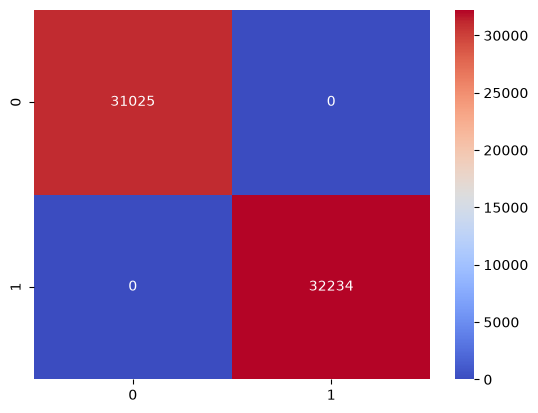

In [11]:
sns.heatmap(confusion, annot=True, cmap="coolwarm", fmt=".0f")
plt.show()

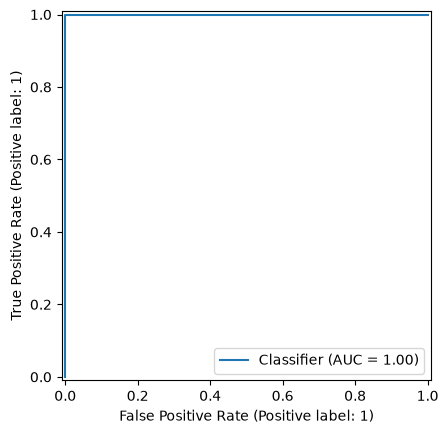

In [12]:
RocCurveDisplay.from_predictions(y_test, y_pred_test)
plt.show()

In [13]:
print(classification_report(y_test, y_pred_test))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     31025
           1       1.00      1.00      1.00     32234

    accuracy                           1.00     63259
   macro avg       1.00      1.00      1.00     63259
weighted avg       1.00      1.00      1.00     63259



## Análise de Resultados
- Após fazermos os **testes preliminares** obtemos um resultado com 100% de aproveitameno -- esse resultado aparentemente perfeito nos traz dúvidas em relação ao desempenho real do modelo.
- Para uma inferência mais robusta e confiável, iremos fazer **validação cruzada** na próxima etapa.
- Através dessa técnica teremos uma visão mais realista e confiável do desempenho do modelo.

In [14]:
# Teste 1: Precisamos descobrir se o teste e o treino são idênticos ou têm interseção
intersection = set(X_train).intersection(set(X_test))
print(f"Quantidade de tweets do teste que também estão no treino: {len(intersection)}")

# Teste 2: Checar se o dataset tem muitas linhas repetidas antes da divisão
print(f"Total de linhas duplicadas no dataset: {train_data.duplicated(subset=['text']).sum()}")


Quantidade de tweets do teste que também estão no treino: 954
Total de linhas duplicadas no dataset: 7933


In [15]:
# Mapeamento das classes
mapping = {0: "Negativo", 1: "Positivo"}

# Testar o Pipeline com novos dados textuais (provenientes dos dados de teste)
random_indexes = np.random.randint(0, len(X_test) -1, 5)
new_data = train_data.loc[random_indexes, "text"] # Separamos os dados para prever
labels = train_data.loc[random_indexes, "sentiments"] # Separamos os rótulos

predictions = nlp_pipeline.predict(new_data)

# Exibir os resultados da previsão
for text, preds, vals in zip(new_data, labels, labels):
    print(f"Texto: {text} -> Classe predita: {mapping[preds]} -> Classe real: {mapping[vals]}")

Texto: ohh yesss move up by jumptags.com -> Classe predita: Positivo -> Classe real: Positivo
Texto: lady and gent mostly lady I think that I be skip openvideo tmrw too much to do -> Classe predita: Negativo -> Classe real: Negativo
Texto: now that s an imtetste visual -> Classe predita: Positivo -> Classe real: Positivo
Texto: I can t believe I be leave in his gaming bag all weekend since thursday night -> Classe predita: Negativo -> Classe real: Negativo
Texto: super diva my friend and I watch jonas movie -> Classe predita: Positivo -> Classe real: Positivo
